# 05 — Forecasting for Operational Planning

## tl;dr

This notebook evaluates whether transparent forecasts improve on simple operational baselines for selected daily store-family series. It uses a chronological 60-day holdout and compares naive, weekly seasonal-naive, Holt-Winters, and Random Forest approaches. The purpose is planning support, not leaderboard optimization.

## Context & Methods

**Forecast target:** next-day sales for selected store-family combinations within the justified 24-month scope.

**Evaluation design:** the final 60 days are held out chronologically. Naive and Random Forest results represent rolling one-day-ahead planning where realized history becomes available each day. Holt-Winters produces a fixed 60-day path from the training cutoff. This difference is reported so the models are not treated as perfectly identical operating procedures.

### Leakage controls

- All lag and rolling features are shifted before use.
- Random splitting is not used.
- Transactions are excluded because future realized transactions would not be known at planning time.
- Calendar, holiday, and promotion-plan fields are treated as known inputs.

In [1]:
from pathlib import Path
import sys
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
# Resolve the repository root dynamically so the notebook works from either
# the project root or the notebooks directory without a local absolute path.
candidate = Path.cwd().resolve()
PROJECT_ROOT = next(
    path for path in (candidate, *candidate.parents)
    if (path / "data").is_dir() and (path / "src").is_dir()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DATA_DIR = PROJECT_ROOT / "outputs" / "processed_data"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"
for directory in (PROCESSED_DATA_DIR, OUTPUT_DATA_DIR, FIGURE_DIR, TABLE_DIR):
    # Creating output folders is safe; raw source files are never modified.
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing

from src.features import add_lag_features
from src.forecasting import forecast_metrics
from src.visualization import PROJECT_COLORS, save_figure, set_project_style

set_project_style()
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
subset_path = OUTPUT_DATA_DIR / "analysis_subset.csv.gz"
if not subset_path.exists():
    raise FileNotFoundError("Run Notebook 02 first to create outputs/processed_data/analysis_subset.csv.gz")
subset = pd.read_csv(subset_path, parse_dates=["date"])
scope = json.loads((OUTPUT_DATA_DIR / "analysis_scope.json").read_text())

## Data

### 1. Select representative forecast series

**Why this step is needed:** Forecast usefulness can vary by demand pattern. Selecting high-volume, high-variability, and typical series tests whether one model behaves consistently across different operational situations.

In [3]:
series_daily = subset.groupby(["store_nbr", "family", "date"], as_index=False, observed=True).agg(
    sales=("sales", "sum"), onpromotion=("onpromotion", "sum"), is_holiday=("is_holiday", "max")
)
series_stats = series_daily.groupby(["store_nbr", "family"])["sales"].agg(mean="mean", std="std", total="sum")
series_stats["cv"] = series_stats["std"] / series_stats["mean"]
eligible = series_stats.loc[series_stats["mean"].gt(0)]

selected_series = []
selected_series.append(tuple(eligible["total"].idxmax()))
selected_series.append(tuple(eligible["cv"].idxmax()))
median_total = eligible["total"].median()
selected_series.append(tuple((eligible["total"] - median_total).abs().idxmin()))
selected_series = list(dict.fromkeys(selected_series))
display(eligible.loc[selected_series])
print("Selected series:", selected_series)

mean       std         total    cv
store_nbr family                                               
45        GROCERY I    11,228.502 4,598.185 8,185,578.291 0.410
32        FROZEN FOODS     33.547    64.326    24,455.974 1.917
          GROCERY I     1,701.058 1,300.112 1,240,071.383 0.764

Selected series: [(np.int64(45), 'GROCERY I'), (np.int64(32), 'FROZEN FOODS'), (np.int64(32), 'GROCERY I')]


## Results

### 2. Fit baselines, Holt-Winters, and Random Forest

**Why this step is needed:** Simple baselines establish the minimum standard a more complex method must beat. Chronological validation and shifted features prevent future information from leaking into training.

In [4]:
validation_days = 60
feature_columns = [
    "lag_1", "lag_7", "lag_14", "lag_28", "rolling_mean_7", "rolling_mean_28",
    "day_of_week", "month", "onpromotion", "is_holiday",
]
results = []
forecast_frames = []

for store_nbr, family in selected_series:
    # Work with one ordered demand series at a time so lags cannot cross stores
    # or product families.
    series = series_daily.loc[
        series_daily["store_nbr"].eq(store_nbr) & series_daily["family"].eq(family)
    ].sort_values("date").copy()
    series["day_of_week"] = series["date"].dt.dayofweek
    series["month"] = series["date"].dt.month
    featured = add_lag_features(series)
    # The most recent 60 observations form a chronological holdout. Random
    # splitting would allow future demand patterns to leak into training.
    train = featured.iloc[:-validation_days].copy()
    validation = featured.iloc[-validation_days:].copy()

    # Operational baselines answer whether a complex model adds useful value.
    predictions = {
        "Naive (lag 1)": validation["lag_1"].to_numpy(),
        "Seasonal naive (lag 7)": validation["lag_7"].to_numpy(),
    }

    # The competition omits a few calendar dates. A simple RangeIndex preserves
    # the observed daily sequence without inventing missing-day sales values.
    hw_training_series = pd.Series(
        train["sales"].to_numpy(), index=pd.RangeIndex(len(train)), name="sales"
    )
    hw_model = ExponentialSmoothing(
        hw_training_series, trend="add", seasonal="add", seasonal_periods=7,
        initialization_method="estimated",
    ).fit(optimized=True, use_brute=False)
    predictions["Holt-Winters"] = np.clip(hw_model.forecast(validation_days).to_numpy(), 0, None)

    # Early rows lack long lags by construction, so only fully observed feature
    # rows can train the model.
    rf_train = train.dropna(subset=feature_columns)
    rf = RandomForestRegressor(
        n_estimators=200, min_samples_leaf=3, max_features=.8,
        random_state=RANDOM_SEED, n_jobs=-1,
    )
    rf.fit(rf_train[feature_columns], rf_train["sales"])
    predictions["Random Forest (rolling 1-day)"] = np.clip(
        rf.predict(validation[feature_columns]), 0, None
    )

    forecast_frame = validation[["date", "sales"]].copy()
    forecast_frame["store_nbr"] = store_nbr
    forecast_frame["family"] = family
    for model_name, predicted in predictions.items():
        forecast_frame[model_name] = np.asarray(predicted)
        metrics = forecast_metrics(validation["sales"], predicted)
        results.append({"store_nbr": store_nbr, "family": family, "model": model_name, **metrics})
    forecast_frames.append(forecast_frame)

model_results = pd.DataFrame(results)
forecasts = pd.concat(forecast_frames, ignore_index=True)
display(model_results.sort_values(["store_nbr", "family", "MAE"]))

,store_nbr,family,model,MAE,RMSE,RMSLE
6,32,FROZEN FOODS,Holt-Winters,7.509,9.659,0.389
5,32,FROZEN FOODS,Seasonal naive (lag 7),8.718,12.270,0.458
7,32,FROZEN FOODS,Random Forest (rolling 1-day),8.830,19.714,0.475
4,32,FROZEN FOODS,Naive (lag 1),9.175,13.083,0.520
11,32,GROCERY I,Random Forest (rolling 1-day),252.303,325.866,0.189
8,32,GROCERY I,Naive (lag 1),315.867,413.818,0.244
9,32,GROCERY I,Seasonal naive (lag 7),385.883,492.613,0.301
10,32,GROCERY I,Holt-Winters,426.265,512.348,0.318
3,45,GROCERY I,Random Forest (rolling 1-day),982.092,"1,433.044",0.110
2,45,GROCERY I,Holt-Winters,"1,507.484","1,847.239",0.150


### 3. Compare average performance and inspect the representative forecast

**Why this step is needed:** Average error summarizes model performance, while the time-series plot shows whether errors cluster around peaks, troughs, or level changes that matter operationally.

,MAE,RMSE,RMSLE
model,,,
Random Forest (rolling 1-day),414.408,592.875,0.258
Holt-Winters,647.086,789.749,0.286
Seasonal naive (lag 7),718.639,945.902,0.315
Naive (lag 1),910.542,"1,104.412",0.334


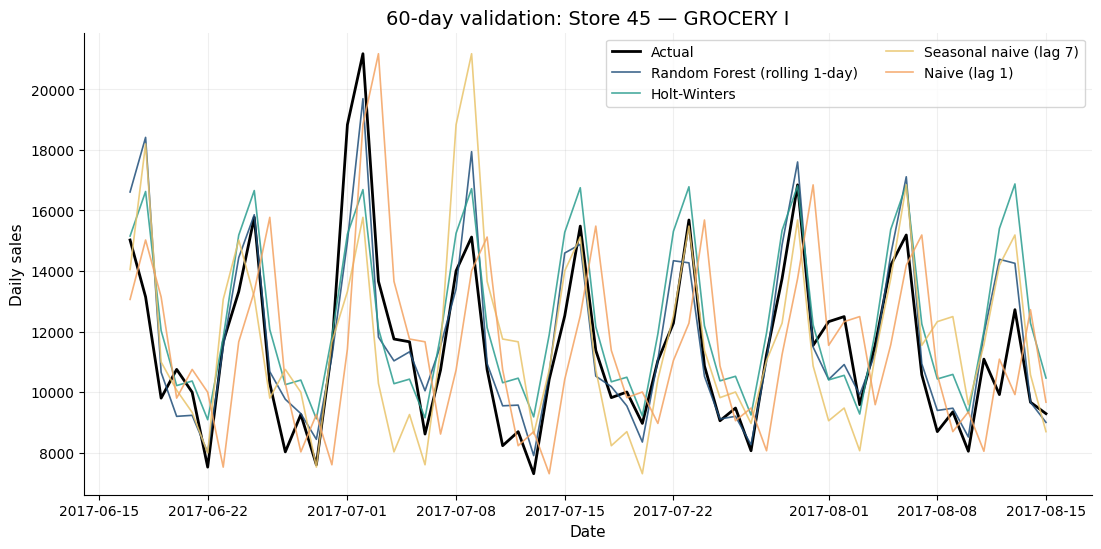

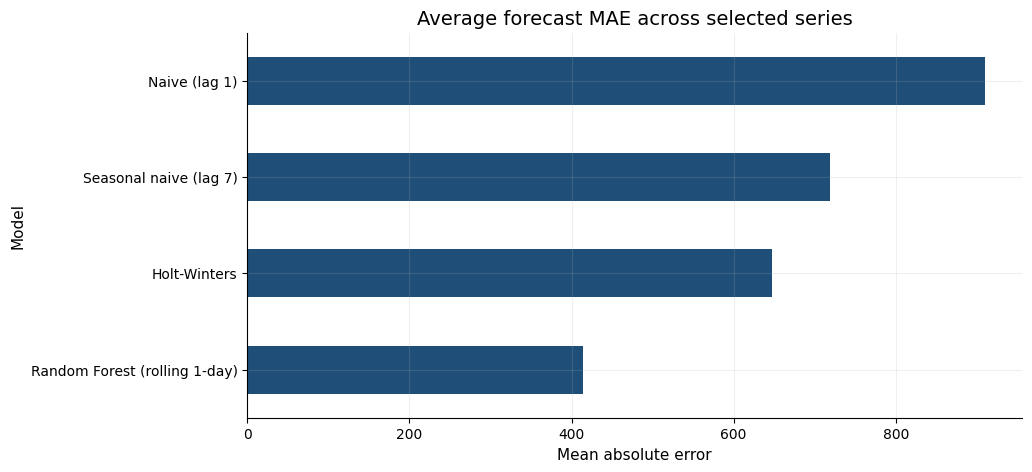

In [5]:
model_average = model_results.groupby("model")[["MAE", "RMSE", "RMSLE"]].mean().sort_values("MAE")
display(model_average)

representative = forecasts.loc[
    forecasts["store_nbr"].eq(selected_series[0][0])
    & forecasts["family"].eq(selected_series[0][1])
].set_index("date")
fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(representative.index, representative["sales"], color="black", linewidth=2, label="Actual")
for index, model_name in enumerate(model_average.index):
    ax.plot(representative.index, representative[model_name], linewidth=1.2, alpha=.85, label=model_name, color=PROJECT_COLORS[index % len(PROJECT_COLORS)])
ax.set(
    title=f"60-day validation: Store {selected_series[0][0]} — {selected_series[0][1]}",
    xlabel="Date", ylabel="Daily sales",
)
ax.legend(ncol=2)
save_figure(fig, FIGURE_DIR, "forecast_01_validation_comparison.png")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
model_average["MAE"].sort_values().plot(kind="barh", ax=ax, color=PROJECT_COLORS[0])
ax.set(title="Average forecast MAE across selected series", xlabel="Mean absolute error", ylabel="Model")
save_figure(fig, FIGURE_DIR, "forecast_02_model_mae.png")
plt.show()

### 4. Check model consistency across demand series

**Why this step is needed:** A model that wins only on average may fail for a particular store-family. Series-level winners test whether a universal model choice is justified.

In [6]:
best_by_series = model_results.loc[model_results.groupby(["store_nbr", "family"])["MAE"].idxmin()]
display(best_by_series[["store_nbr", "family", "model", "MAE", "RMSE", "RMSLE"]])
print("Best-model counts:")
display(best_by_series["model"].value_counts())

,store_nbr,family,model,MAE,RMSE,RMSLE
6,32,FROZEN FOODS,Holt-Winters,7.509,9.659,0.389
11,32,GROCERY I,Random Forest (rolling 1-day),252.303,325.866,0.189
3,45,GROCERY I,Random Forest (rolling 1-day),982.092,"1,433.044",0.110


Best-model counts:


model
Random Forest (rolling 1-day)    2
Holt-Winters                     1
Name: count, dtype: int64

### 5. Save forecast evidence

**Why this step is needed:** Saving metrics and validation predictions creates an auditable record for the report and allows future model changes to be compared against the same holdout evidence.

In [7]:
model_results.to_csv(TABLE_DIR / "forecast_model_results.csv", index=False)
model_average.reset_index().to_csv(TABLE_DIR / "forecast_model_average.csv", index=False)
best_by_series.to_csv(TABLE_DIR / "forecast_best_by_series.csv", index=False)
forecasts.to_csv(PROJECT_ROOT / "outputs" / "forecasts" / "validation_forecasts.csv", index=False)
print("Saved model metrics and validation forecasts.")

Saved model metrics and validation forecasts.


## Takeaways

In [8]:
best_model = model_average.index[0]
best_mae = model_average.iloc[0]["MAE"]
seasonal_mae = model_average.loc["Seasonal naive (lag 7)", "MAE"]
improvement = 100 * (seasonal_mae - best_mae) / seasonal_mae
display(Markdown(f'''
- **{best_model}** has the lowest average MAE (**{best_mae:,.2f}**) across the selected series.
- Relative to the weekly seasonal-naive baseline, its average MAE difference is **{improvement:,.1f}%**; this measures the chosen validation setup, not a guaranteed business improvement.
- Model winners vary by series, so operational deployment should retain a simple baseline and monitor performance by store-family rather than selecting one universal model solely from an overall average.
- The rolling Random Forest uses only lagged realized sales plus known calendar/promotion/holiday inputs; realized future transactions are excluded.
- Forecasts can support short-horizon planning, but translating error reduction into inventory or service improvements requires stock, lead-time, cost, and service-level data that this dataset does not contain.
'''))


- **Random Forest (rolling 1-day)** has the lowest average MAE (**414.41**) across the selected series.
- Relative to the weekly seasonal-naive baseline, its average MAE difference is **42.3%**; this measures the chosen validation setup, not a guaranteed business improvement.
- Model winners vary by series, so operational deployment should retain a simple baseline and monitor performance by store-family rather than selecting one universal model solely from an overall average.
- The rolling Random Forest uses only lagged realized sales plus known calendar/promotion/holiday inputs; realized future transactions are excluded.
- Forecasts can support short-horizon planning, but translating error reduction into inventory or service improvements requires stock, lead-time, cost, and service-level data that this dataset does not contain.
